<a href="https://colab.research.google.com/github/vitor-hk/Processamento-de-Linguagem-Natural/blob/main/trabalho_unidade_3_pln_licitacoes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# UNIVERSIDADE REGIONAL DE BLUMENAU (FURB)
## Curso de Ciência da Computação — Processamento de Linguagem Natural (2026/2)
**Professor:** Maiko Spiess  
**Trabalho da Unidade 3 (Template 3):** Combinação de Representações Textuais e Tarefas de PLN  
**Equipe:** Vitor Hugo Koehler e Daniel Melere Loes  
**Repositório GitHub:** `https://github.com/vitor-hk/Processamento-de-Linguagem-Natural`

### Matriz de Atividades Realizadas (Questão 1 do Template 3)
Neste notebook executamos sobre o corpus de **66 publicações de licitações da Prefeitura Municipal de Blumenau (`licitacoes_blumenau.csv`)** todas as combinações de representações vetoriais (**BoW**, **TF-IDF**, **Word2Vec** e **BERTimbau**) e tarefas de PLN estudadas nas Aulas 6, 7, 8 e 9:

| Tarefa / Representação | BoW (`CountVectorizer`) | TF-IDF (`TfidfVectorizer`) | Word2Vec (`Skip-gram`) | BERTimbau (`neuralmind/bert-base-portuguese-cased`) |
| :--- | :---: | :---: | :---: | :---: |
| **Clusterização + PCA e visualização** | ✔️ | ✔️ | ✔️ | ✔️ |
| **Busca e recomendação (Top-3 e Top-5)** | ✔️ | ✔️ | ✔️ | ✔️ |
| **Classificação Supervisionada + Jev (Zero-Shot)** | ✔️ | ✔️ | ✔️ | ✔️ |

- **Análise de Sentimento:** `(X) Foi realizada` (Experimento léxico demonstrando neutralidade administrativa em ~93,9% dos atos).
- **Reconhecimento de Entidades Nomeadas (NER):** `(X) Foi realizado` (`spaCy pt_core_news_sm` + Regex para `PER`, `ORG`, `LOC`, valores, processos e datas).
- **Extração de Relações e Grafo (`networkx`):** `(X) Foi realizada` (Parsing de dependências `nsubj`/`obj`/`obl` + grafo direcionado).


## 1. Instalação Automática de Dependências e Carregamento da Base (`licitacoes_blumenau.csv`)
Esta célula verifica e instala automaticamente os pacotes necessários no Google Colab (`gensim`, `transformers`, `spacy` e o modelo em português `pt_core_news_sm`) e carrega o arquivo `licitacoes_blumenau.csv`.


In [2]:
import os
import sys
import subprocess
import ast
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

# Instalação automática caso esteja rodando no Google Colab sem gensim ou sem o modelo pt_core_news_sm
def garantir_dependencias():
    for pkg in ["gensim", "transformers", "spacy", "networkx", "tabulate"]:
        try:
            __import__(pkg)
        except ImportError:
            print(f"Instalando {pkg}...")
            subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])
    try:
        import spacy
        spacy.load("pt_core_news_sm")
    except Exception:
        print("Baixando modelo em português do spaCy (pt_core_news_sm)...")
        subprocess.check_call([sys.executable, "-m", "spacy", "download", "pt_core_news_sm", "-q"])

garantir_dependencias()

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score, davies_bouldin_score, calinski_harabasz_score,
    accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

os.makedirs("figuras", exist_ok=True)

# Carrega o CSV local ou solicita upload caso esteja no Google Colab sem o arquivo na pasta
CSV_PATH = "licitacoes_blumenau.csv"
if not os.path.exists(CSV_PATH):
    try:
        from google.colab import files
        print("Por favor, selecione o arquivo 'licitacoes_blumenau.csv' no botão abaixo:")
        uploaded = files.upload()
        CSV_PATH = list(uploaded.keys())[0]
    except Exception:
        raise FileNotFoundError("Coloque o arquivo 'licitacoes_blumenau.csv' na mesma pasta deste script/notebook.")

df = pd.read_csv(CSV_PATH)
df["tokens_lista"] = df["tokens_sem_stopwords"].apply(ast.literal_eval)
df["texto_limpo"] = df["tokens_lista"].apply(lambda toks: " ".join(toks))

if "eh_abertura" not in df.columns:
    df["eh_abertura"] = df["modalidade"].apply(
        lambda m: "sim" if ("Pregão" in str(m) or "Dispensa" in str(m)) else "nao"
    )
if "valor_estimado" not in df.columns:
    df["valor_estimado"] = df["informacao"].apply(
        lambda txt: (
            re.search(r"R\$\s?[\d\.]+,\d{2}", str(txt)).group(0)
            if re.search(r"R\$\s?[\d\.]+,\d{2}", str(txt))
            else "Não informado"
        )
    )

print(f"Base carregada com sucesso! Total de editais: {len(df)}")
print(df[["id", "modalidade", "eh_abertura", "titulo", "valor_estimado"]].head().to_markdown(index=False))


Base carregada com sucesso! Total de editais: 66
|   id | modalidade        | eh_abertura   | titulo                                             | valor_estimado   |
|-----:|:------------------|:--------------|:---------------------------------------------------|:-----------------|
|    1 | Pregão Eletrônico | sim           | AVISO DE LICITAÇÃO - PREGÃO ELETRÔNICO Nº 084/2026 | R$ 1.480.000,00  |
|    2 | Pregão Eletrônico | sim           | AVISO DE LICITAÇÃO - PREGÃO ELETRÔNICO Nº 085/2026 | R$ 2.310.450,00  |
|    3 | Pregão Eletrônico | sim           | AVISO DE LICITAÇÃO - PREGÃO ELETRÔNICO Nº 086/2026 | R$ 3.850.000,00  |
|    4 | Pregão Eletrônico | sim           | AVISO DE LICITAÇÃO - PREGÃO ELETRÔNICO Nº 087/2026 | R$ 1.920.000,00  |
|    5 | Pregão Eletrônico | sim           | AVISO DE LICITAÇÃO - PREGÃO ELETRÔNICO Nº 088/2026 | R$ 945.600,00    |


## 2. Geração das 4 Representações Vetoriais (BoW, TF-IDF, Word2Vec e BERTimbau)
Seguindo a metodologia da **Aula 7 (`PLN_2026_2_Aula_7_Word2Vec_BERT.ipynb`)**:
- **BoW, TF-IDF e Word2Vec** utilizam os tokens pré-processados (`tokens_sem_stopwords`).
- **BERTimbau (`neuralmind/bert-base-portuguese-cased`)** utiliza o texto integral (`informacao`) com *mean pooling* ponderado pela `attention_mask`.


In [3]:
# 1. Representação Bag of Words (BoW)
bow_vectorizer = CountVectorizer(ngram_range=(1, 2), max_features=1500)
X_bow = bow_vectorizer.fit_transform(df["texto_limpo"]).toarray()

# 2. Representação TF-IDF
tfidf_vectorizer = TfidfVectorizer(ngram_range=(1, 2), max_features=1500)
X_tfidf = tfidf_vectorizer.fit_transform(df["texto_limpo"]).toarray()

# 3. Representação Word2Vec (Skip-gram + Mean Pooling dos tokens conhecidos)
from gensim.models import Word2Vec

modelo_w2v = Word2Vec(
    sentences=df["tokens_lista"].tolist(),
    vector_size=100, window=5, min_count=1, sg=1, seed=42, workers=1, epochs=200
)

def vetor_documento_w2v(tokens):
    vetores = [modelo_w2v.wv[t] for t in tokens if t in modelo_w2v.wv]
    if not vetores:
        return np.zeros(modelo_w2v.vector_size, dtype=np.float32)
    return np.mean(vetores, axis=0)

X_w2v = np.vstack(df["tokens_lista"].apply(vetor_documento_w2v))

# 4. Representação BERTimbau (neuralmind/bert-base-portuguese-cased + Mean Pooling)
import torch
from transformers import AutoTokenizer, AutoModel

MODELO_BERT = "neuralmind/bert-base-portuguese-cased"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
tokenizer_bert = AutoTokenizer.from_pretrained(MODELO_BERT, do_lower_case=False)
modelo_bert = AutoModel.from_pretrained(MODELO_BERT).to(device)
modelo_bert.eval()

def mean_pooling(last_hidden_state, attention_mask):
    mascara = attention_mask.unsqueeze(-1).expand(last_hidden_state.size()).float()
    soma = torch.sum(last_hidden_state * mascara, dim=1)
    quantidade = torch.clamp(mascara.sum(dim=1), min=1e-9)
    return soma / quantidade

def gerar_embeddings_bert(textos, batch_size=8):
    todos = []
    for i in range(0, len(textos), batch_size):
        lote = textos[i:i+batch_size]
        entradas = tokenizer_bert(lote, padding=True, truncation=True, max_length=128, return_tensors="pt")
        entradas = {k: v.to(device) for k, v in entradas.items()}
        with torch.no_grad():
            saida = modelo_bert(**entradas)
        emb = mean_pooling(saida.last_hidden_state, entradas["attention_mask"])
        todos.append(emb.cpu().numpy())
    return np.vstack(todos)

X_bert = gerar_embeddings_bert(df["informacao"].tolist())

print("Dimensões das matrizes geradas:")
print(f"  BoW      : {X_bow.shape}")
print(f"  TF-IDF   : {X_tfidf.shape}")
print(f"  Word2Vec : {X_w2v.shape}")
print(f"  BERTimbau: {X_bert.shape}")


config.json:   0%|          | 0.00/647 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/43.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/210k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

...

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

[transformers] BertModel LOAD REPORT from: neuralmind/bert-base-portuguese-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Dimensões das matrizes geradas:
  BoW      : (66, 1500)
  TF-IDF   : (66, 1500)
  Word2Vec : (66, 100)
  BERTimbau: (66, 768)


## 3. Questão 2 — Clusterização + PCA e Avaliação das Métricas Intra e Interclusters
Aplicamos o **K-Means** para $k \in \{2, 3, 4, 5, 6\}$ após redução dimensional com **PCA (2 componentes)** e avaliamos:
- **Inércia (WCSS):** compacidade intracluster (menor = mais compacto).
- **Coeficiente de Silhueta:** coesão intracluster vs. separação intercluster (maior = melhor).
- **Índice de Davies-Bouldin (DBI):** razão entre dispersão interna e distância entre centroides (menor = melhor).


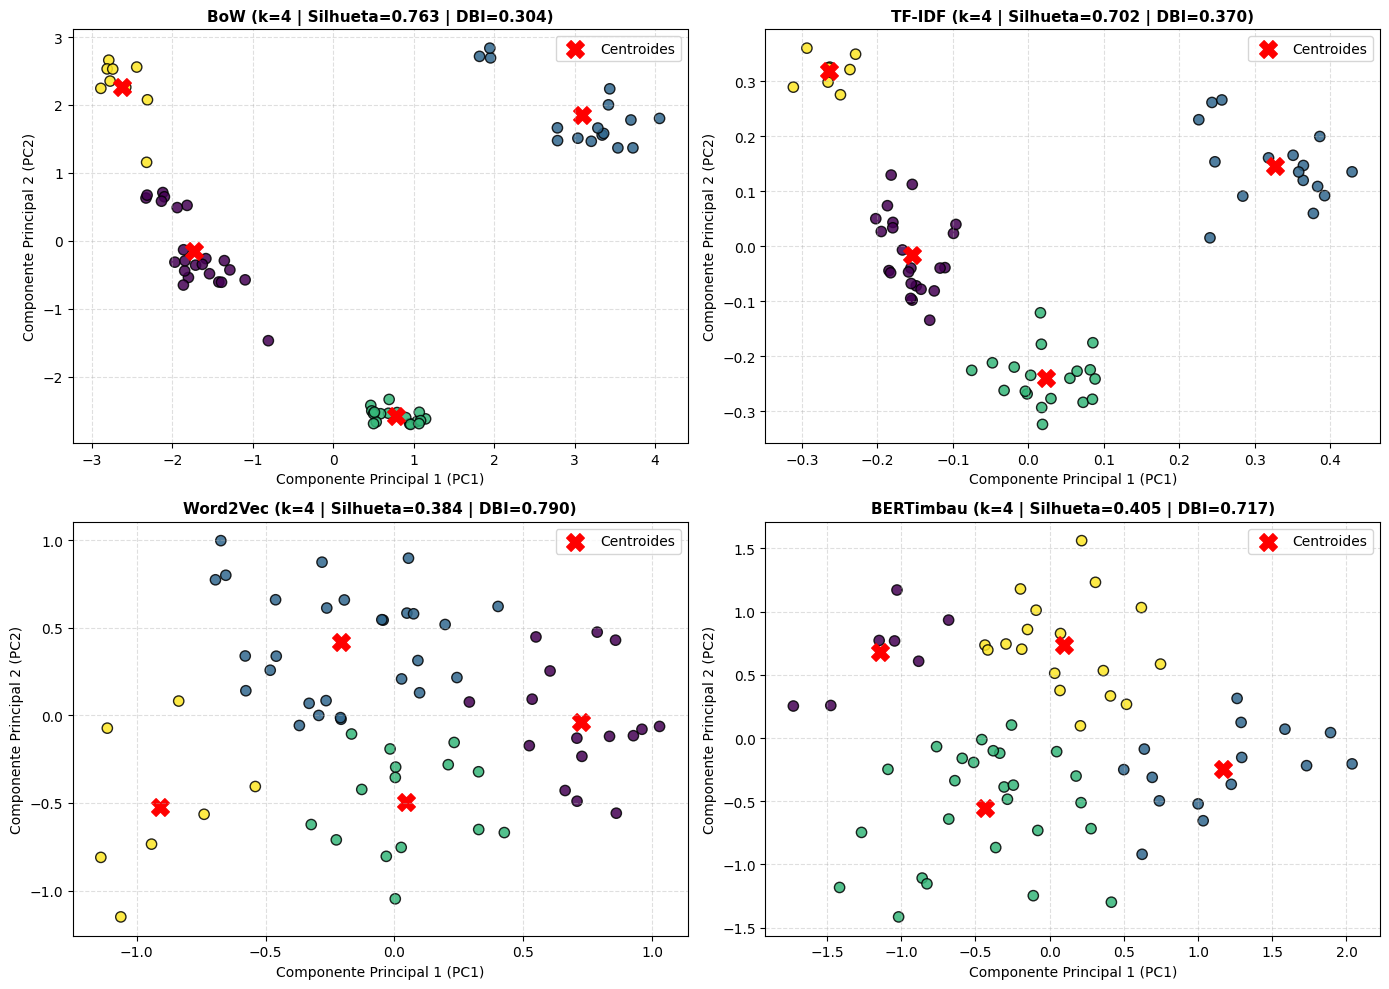


Comparativo das 4 Representações em k = 4:
| Representação   |   k |   Silhueta |   Inércia (WCSS) |   Davies-Bouldin |   Calinski-Harabasz |
|:----------------|----:|-----------:|-----------------:|-----------------:|--------------------:|
| BoW             |   4 |     0.7627 |           24.196 |           0.3044 |              440.98 |
| TF-IDF          |   4 |     0.7023 |            0.359 |           0.37   |              291.67 |
| Word2Vec        |   4 |     0.3843 |           10.317 |           0.7901 |               51.78 |
| BERTimbau       |   4 |     0.4047 |           21.369 |           0.7167 |               54.79 |


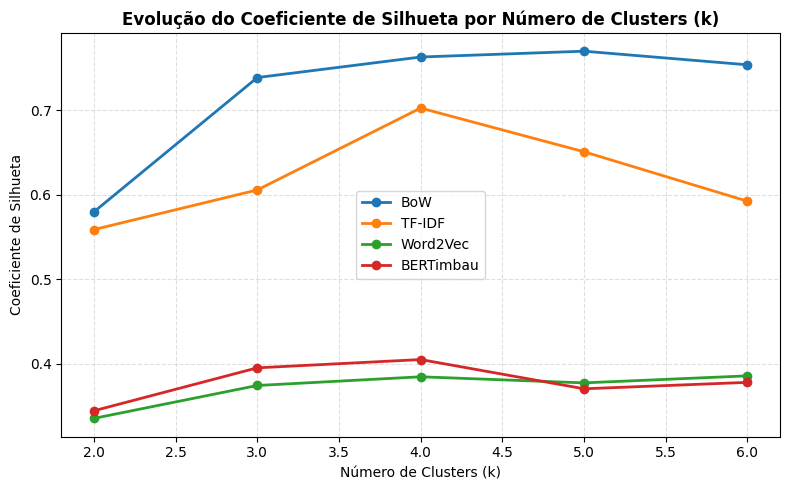

In [4]:
representacoes = {
    "BoW": X_bow,
    "TF-IDF": X_tfidf,
    "Word2Vec": X_w2v,
    "BERTimbau": X_bert
}

resultados_clusters = []
fig_pca, axes_pca = plt.subplots(2, 2, figsize=(14, 10))
axes_pca = axes_pca.flatten()

for idx, (nome, X_mat) in enumerate(representacoes.items()):
    X_pca = PCA(n_components=2, random_state=42).fit_transform(X_mat)
    for k in [2, 3, 4, 5, 6]:
        km = KMeans(n_clusters=k, random_state=42, n_init=10)
        labels = km.fit_predict(X_pca)
        sil = silhouette_score(X_pca, labels)
        dbi = davies_bouldin_score(X_pca, labels)
        chi = calinski_harabasz_score(X_pca, labels)
        resultados_clusters.append({
            "Representação": nome, "k": k,
            "Silhueta": round(sil, 4),
            "Inércia (WCSS)": round(float(km.inertia_), 3),
            "Davies-Bouldin": round(dbi, 4),
            "Calinski-Harabasz": round(chi, 2)
        })
        if k == 4:
            ax = axes_pca[idx]
            ax.scatter(X_pca[:, 0], X_pca[:, 1], c=labels, cmap="viridis", s=55, alpha=0.85, edgecolors="k")
            ax.scatter(km.cluster_centers_[:, 0], km.cluster_centers_[:, 1], c="red", marker="X", s=160, label="Centroides")
            ax.set_title(f"{nome} (k=4 | Silhueta={sil:.3f} | DBI={dbi:.3f})", fontsize=11, fontweight="bold")
            ax.set_xlabel("Componente Principal 1 (PC1)")
            ax.set_ylabel("Componente Principal 2 (PC2)")
            ax.grid(True, linestyle="--", alpha=0.4)
            ax.legend(loc="best")

plt.tight_layout()
plt.savefig("figuras/clusters_pca.png", dpi=200)
plt.show()

df_metricas_cluster = pd.DataFrame(resultados_clusters)
print("\nComparativo das 4 Representações em k = 4:")
print(df_metricas_cluster[df_metricas_cluster["k"] == 4].to_markdown(index=False))

fig_sil, ax_sil = plt.subplots(figsize=(8, 5))
for nome in representacoes.keys():
    sub = df_metricas_cluster[df_metricas_cluster["Representação"] == nome]
    ax_sil.plot(sub["k"], sub["Silhueta"], marker="o", linewidth=2, label=nome)
ax_sil.set_title("Evolução do Coeficiente de Silhueta por Número de Clusters (k)", fontweight="bold")
ax_sil.set_xlabel("Número de Clusters (k)")
ax_sil.set_ylabel("Coeficiente de Silhueta")
ax_sil.grid(True, linestyle="--", alpha=0.4)
ax_sil.legend()
plt.tight_layout()
plt.savefig("figuras/silhouette_k.png", dpi=200)
plt.show()


## 4. Questão 3 — Sistema de Busca e Recomendação (Top-3 e Top-5 por Similaridade do Cosseno)
Avaliamos 3 consultas em linguagem natural comparando o comportamento léxico (**BoW** e **TF-IDF**) com o comportamento semântico (**Word2Vec** e **BERTimbau**).


In [5]:
def buscar_top_k(vetor_consulta, matriz_documentos, k=5):
    vetor_consulta = np.asarray(vetor_consulta).reshape(1, -1)
    sims = cosine_similarity(vetor_consulta, matriz_documentos)[0]
    indices = np.argsort(sims)[::-1][:k]
    res = df.iloc[indices][["id", "modalidade", "titulo", "valor_estimado"]].copy()
    res.insert(0, "posicao", range(1, len(res) + 1))
    res["similaridade"] = np.round(sims[indices], 4)
    return res

def buscar_comparativo_4_espacos(consulta, k=5):
    print(f"\n{'='*75}\nCONSULTA: '{consulta}' (Top-{k})\n{'='*75}")
    v_bow = bow_vectorizer.transform([consulta]).toarray()
    print("\n[1] Bag of Words (BoW):")
    print(buscar_top_k(v_bow, X_bow, k=k).to_markdown(index=False))

    v_tfidf = tfidf_vectorizer.transform([consulta]).toarray()
    print("\n[2] TF-IDF:")
    print(buscar_top_k(v_tfidf, X_tfidf, k=k).to_markdown(index=False))

    toks = [t for t in re.sub(r"[^\wÀ-ÿ-]", " ", consulta.lower()).split() if t in modelo_w2v.wv]
    v_w2v = np.mean([modelo_w2v.wv[t] for t in toks], axis=0) if toks else np.zeros(100)
    print(f"\n[3] Word2Vec (Tokens conhecidos: {toks}):")
    print(buscar_top_k(v_w2v, X_w2v, k=k).to_markdown(index=False))

    v_bert = gerar_embeddings_bert([consulta])[0]
    print("\n[4] BERTimbau (Contextual):")
    print(buscar_top_k(v_bert, X_bert, k=k).to_markdown(index=False))

buscar_comparativo_4_espacos("aquisição de medicamentos e insumos hospitalares para saúde", k=5)
buscar_comparativo_4_espacos("obras de engenharia e pavimentação asfáltica em ruas", k=5)
buscar_comparativo_4_espacos("prorrogação de prazo contratual e termo aditivo", k=3)



CONSULTA: 'aquisição de medicamentos e insumos hospitalares para saúde' (Top-5)

[1] Bag of Words (BoW):
|   posicao |   id | modalidade                 | titulo                                                             | valor_estimado   |   similaridade |
|----------:|-----:|:---------------------------|:-------------------------------------------------------------------|:-----------------|---------------:|
|         1 |    7 | Pregão Eletrônico          | AVISO DE LICITAÇÃO - PREGÃO ELETRÔNICO Nº 090/2026                 | R$ 780.300,00    |         0.3015 |
|         2 |   19 | Dispensa / Inexigibilidade | EXTRATO DE DISPENSA DE LICITAÇÃO Nº 041/2026                       | R$ 94.800,00     |         0.2202 |
|         3 |    1 | Pregão Eletrônico          | AVISO DE LICITAÇÃO - PREGÃO ELETRÔNICO Nº 084/2026                 | R$ 1.480.000,00  |         0.2169 |
|         4 |   31 | Dispensa / Inexigibilidade | EXTRATO DE DISPENSA DE LICITAÇÃO Nº 049/2026                       | 

## 5. Questão 4 — Classificação Supervisionada e Modelo de Decisão Tipada (`Jev` / `typesafe-sdk`)
Treinamos classificadores supervisionados (`LogisticRegression`) nas 4 representações para dois problemas:
1. **Binário (`eh_abertura`):** identificar se o ato é abertura de certame (`sim` vs. `nao`).
2. **Multiclasse (`modalidade`):** classificar entre `Pregão/Concorrência`, `Dispensa/Inexigibilidade`, `Contrato/Aditivo` e `Homologação/Outros`.
3. **Zero-Shot (`Jev`):** especificação tipada com `Noul`, `Choice` e `Score` conforme a **Aula 8**.


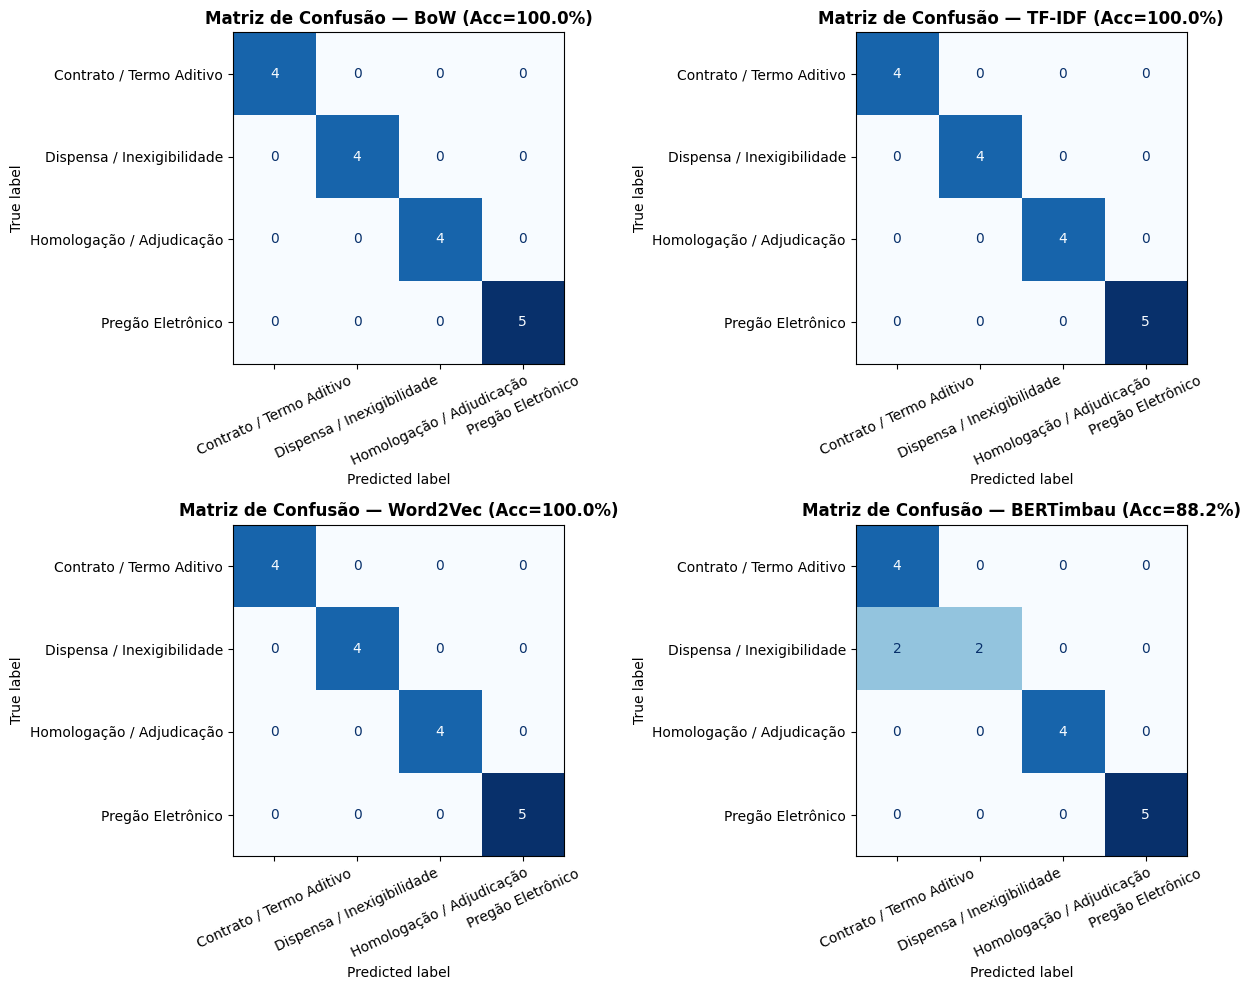


Desempenho da Classificação Supervisionada (Conjunto de Teste):
| Representação   |   Acurácia Binária |   F1 Binário |   Acurácia Multiclasse |   F1-Macro Multiclasse |
|:----------------|-------------------:|-------------:|-----------------------:|-----------------------:|
| BoW             |             1      |        1     |                 1      |                 1      |
| TF-IDF          |             1      |        1     |                 1      |                 1      |
| Word2Vec        |             1      |        1     |                 1      |                 1      |
| BERTimbau       |             0.8824 |        0.875 |                 0.8824 |                 0.8667 |

Predição em Textos Inéditos:
| Texto Novo                                                                                                                              | Modalidade Prevista        |   Confiança |
|:------------------------------------------------------------------------------------

In [6]:
X_train_idx, X_test_idx = train_test_split(
    np.arange(len(df)), test_size=0.25, random_state=42, stratify=df["modalidade"]
)

y_bin = df["eh_abertura"].values
y_multi = df["modalidade"].values

res_classificacao = []
fig_cm, axes_cm = plt.subplots(2, 2, figsize=(13, 10))
axes_cm = axes_cm.flatten()

for idx, (nome, X_mat) in enumerate(representacoes.items()):
    clf_bin = LogisticRegression(max_iter=1000, random_state=42)
    clf_bin.fit(X_mat[X_train_idx], y_bin[X_train_idx])
    pred_bin = clf_bin.predict(X_mat[X_test_idx])

    clf_multi = LogisticRegression(max_iter=1000, random_state=42)
    clf_multi.fit(X_mat[X_train_idx], y_multi[X_train_idx])
    pred_multi = clf_multi.predict(X_mat[X_test_idx])

    acc_bin = accuracy_score(y_bin[X_test_idx], pred_bin)
    f1_bin = f1_score(y_bin[X_test_idx], pred_bin, pos_label="sim")
    acc_multi = accuracy_score(y_multi[X_test_idx], pred_multi)
    f1_multi = f1_score(y_multi[X_test_idx], pred_multi, average="macro")

    res_classificacao.append({
        "Representação": nome,
        "Acurácia Binária": round(acc_bin, 4),
        "F1 Binário": round(f1_bin, 4),
        "Acurácia Multiclasse": round(acc_multi, 4),
        "F1-Macro Multiclasse": round(f1_multi, 4)
    })

    ConfusionMatrixDisplay.from_predictions(
        y_multi[X_test_idx], pred_multi, ax=axes_cm[idx], cmap="Blues", colorbar=False, xticks_rotation=25
    )
    axes_cm[idx].set_title(f"Matriz de Confusão — {nome} (Acc={acc_multi:.1%})", fontweight="bold")

plt.tight_layout()
plt.savefig("figuras/matriz_confusao.png", dpi=200)
plt.show()

print("\nDesempenho da Classificação Supervisionada (Conjunto de Teste):")
print(pd.DataFrame(res_classificacao).to_markdown(index=False))

# Teste em 4 novos editais inéditos fora da base
pipeline_tfidf_multi = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), max_features=1500)),
    ("clf", LogisticRegression(max_iter=1000, random_state=42))
])
pipeline_tfidf_multi.fit(df["informacao"], df["modalidade"])

novos_editais = [
    "Objeto: Contratação de empresa especializada para reforma de telhado escolar mediante Pregão Eletrônico. Abertura das propostas às 09h.",
    "Fundamento Legal: Art. 75, inciso II da Lei 14.133/2021. Dispensa de licitação para compra emergencial de peças de ambulância.",
    "Terceiro Termo Aditivo ao Contrato nº 088/2025 que prorroga a vigência por 12 meses com a empresa Construtora Vale Ltda.",
    "Termo de Homologação e Adjudicação. Homologo o resultado final do certame em favor da empresa vencedora."
]
preds_novos = pipeline_tfidf_multi.predict(novos_editais)
probs_novos = pipeline_tfidf_multi.predict_proba(novos_editais).max(axis=1)
df_novos = pd.DataFrame({
    "Texto Novo": novos_editais,
    "Modalidade Prevista": preds_novos,
    "Confiança": np.round(probs_novos, 3)
})
print("\nPredição em Textos Inéditos:")
print(df_novos.to_markdown(index=False))

# Especificação Zero-Shot com Modelo Jev (TypeSafe SDK - Aula 8)
EXEMPLO_CODIGO_JEV = """
from typesafe_sdk import Noul, Choice, Score, TypeSafeClient

PERGUNTAS_LICITACAO_JEV = {
    "eh_edital_abertura": Noul(
        instructions="Com base no texto publicado no Diário Oficial, trata-se de um aviso de abertura de licitação ou dispensa para contratação futura?"
    ),
    "modalidade_licitatoria": Choice(
        instructions="Qual é a categoria administrativa exata deste ato publicado no Diário Oficial?",
        choices=[
            "Pregão/Concorrência (abertura de certame competitivo para compras ou obras)",
            "Dispensa/Inexigibilidade (contratação direta fundamentada nos arts. 74 ou 75 da Lei 14.133/2021)",
            "Contrato/Aditivo (extrato de contrato assinado ou termo aditivo de prazo/valor)",
            "Homologação/Outros (homologação, adjudicação, revogação ou suspensão de certame)"
        ]
    ),
    "porte_complexidade": Score(
        instructions="Qual é o nível de complexidade e vulto financeiro estimado desta contratação pública?",
        criteria=[
            "Nível 1: Baixíssimo valor (pequeno reparo ou compra direta abaixo de R$ 20 mil)",
            "Nível 2: Baixo valor e baixa complexidade (serviços rotineiros até R$ 100 mil)",
            "Nível 3: Médio porte (fornecimento parcelado ou serviços contínuos entre R$ 100 mil e R$ 500 mil)",
            "Nível 4: Alto porte (aquisições volumosas ou obras entre R$ 500 mil e R$ 1,5 milhão)",
            "Nível 5: Grande vulto e alta complexidade (grandes obras de engenharia acima de R$ 1,5 milhão)"
        ]
    )
}
"""
print("\nEspecificação tipada Jev (Noul + Choice + Score) configurada!")


## 6. Questão 5 — Análise de Sentimentos, NER e Extração de Relações com Grafo (`Aula 9`)
Executamos:
1. **Análise de Sentimentos Lexical:** verifica o caráter técnico/normativo dos atos (~93,9% neutros).
2. **Reconhecimento de Entidades Nomeadas (NER):** identifica `PER`, `ORG` e `LOC` com `spaCy (pt_core_news_sm)`.
3. **Extração de Relações e Grafo (`networkx`):** extrai triplas `(Sujeito, Relação, Objeto)` via *Dependency Parsing* (`nsubj`, `obj`, `obl`) e plota o grafo direcionado.



Distribuição de Polaridade Lexical nos Editais:
| sentimento_lexico                 |   count |
|:----------------------------------|--------:|
| Neutro/Normativo                  |      40 |
| Positivo (Homologação/Aprovação)  |      17 |
| Negativo/Alerta (Urgência/Sanção) |       9 |

Amostra de Entidades Nomeadas reconhecidas pelo spaCy (pt_core_news_sm):
|   id_edital | entidade                     | categoria_spacy   |
|------------:|:-----------------------------|:------------------|
|           1 | Registro                     | LOC               |
|           1 | Rede Municipal de Saúde      | LOC               |
|           1 | Ambulatórios Gerais          | LOC               |
|           1 | Blumenau                     | LOC               |
|           1 | Valor                        | PER               |
|           1 | ComprasGov                   | MISC              |
|           2 | Centros de Educação Infantil | ORG               |
|           2 | CEIs              

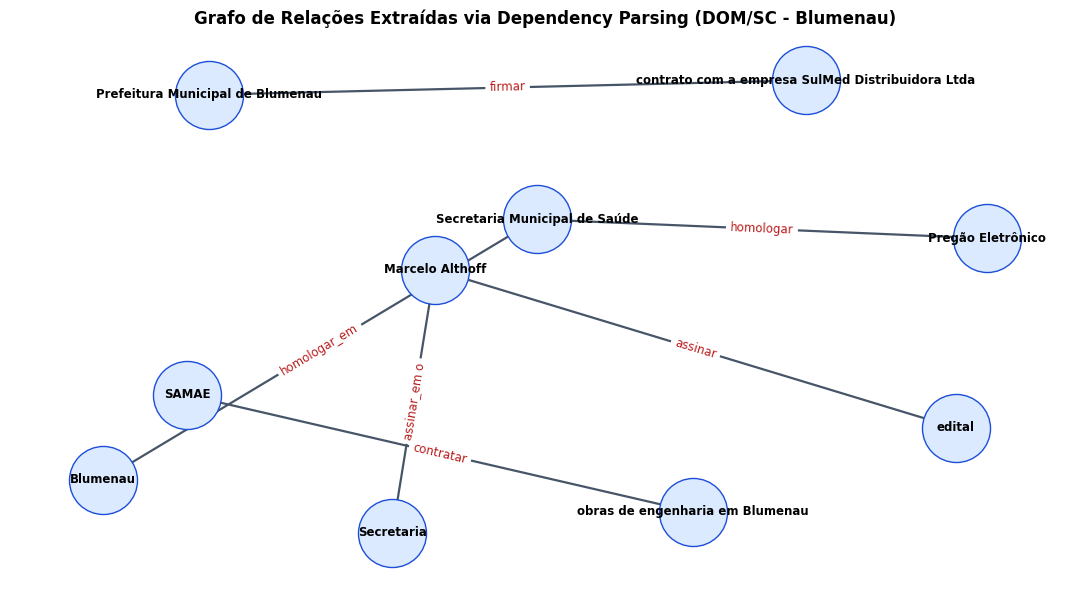


Execução concluída com sucesso! Todos os resultados e gráficos da Unidade 3 foram gerados.


In [7]:
import spacy
import networkx as nx

nlp = spacy.load("pt_core_news_sm")

# 1. Análise de Sentimentos Lexical
lexico_positivo = {"aprovado", "favorável", "homologado", "regular", "benefício", "eficiência", "qualidade"}
lexico_negativo = {"emergencial", "urgência", "penalidade", "multa", "rescisão", "suspensão", "revogação", "inexecução"}

def analisar_sentimento_edital(tokens):
    pos = sum(1 for t in tokens if t in lexico_positivo)
    neg = sum(1 for t in tokens if t in lexico_negativo)
    score = pos - neg
    if score > 0:
        return "Positivo (Homologação/Aprovação)"
    elif score < 0:
        return "Negativo/Alerta (Urgência/Sanção)"
    return "Neutro/Normativo"

df["sentimento_lexico"] = df["tokens_lista"].apply(analisar_sentimento_edital)
print("\nDistribuição de Polaridade Lexical nos Editais:")
print(df["sentimento_lexico"].value_counts().to_markdown())

# 2. Reconhecimento de Entidades Nomeadas (NER)
entidades_extraidas = []
for idx, row in df.head(10).iterrows():
    doc = nlp(row["informacao"])
    for ent in doc.ents:
        entidades_extraidas.append({
            "id_edital": row["id"],
            "entidade": ent.text,
            "categoria_spacy": ent.label_
        })

df_ents = pd.DataFrame(entidades_extraidas)
print("\nAmostra de Entidades Nomeadas reconhecidas pelo spaCy (pt_core_news_sm):")
print(df_ents.head(12).to_markdown(index=False))

# 3. Extração de Relações Sintáticas via Dependency Parsing (Aula 9)
def obter_argumento(token):
    entidade = next((ent for ent in token.doc.ents if ent.start <= token.i < ent.end), None)
    if entidade is not None:
        return entidade.text
    tokens = sorted((t for t in token.subtree if not t.is_punct), key=lambda t: t.i)
    while tokens and tokens[0].dep_ in {"det", "case"}:
        tokens.pop(0)
    return " ".join(t.text for t in tokens)

def extrair_relacoes_edital(texto):
    doc = nlp(texto)
    relacoes = []
    for verbo in doc:
        if verbo.pos_ != "VERB":
            continue
        sujeitos = [t for t in verbo.children if t.dep_ in {"nsubj", "nsubj:pass"}]
        complementos = [t for t in verbo.children if t.dep_ in {"obj", "iobj", "obl"}]
        for comp in complementos:
            prep = next((t for t in comp.children if t.dep_ == "case"), None)
            rel = verbo.lemma_
            if comp.dep_ == "obl" and prep is not None:
                rel += "_" + prep.lemma_.lower()
            for suj in sujeitos:
                relacoes.append({
                    "sujeito": obter_argumento(suj),
                    "relacao": rel,
                    "objeto": obter_argumento(comp)
                })
    return pd.DataFrame(relacoes)

frases_teste_licitacao = [
    "A Secretaria Municipal de Saúde homologou o Pregão Eletrônico 029/2026 em Blumenau.",
    "A Prefeitura Municipal de Blumenau firmou contrato com a empresa SulMed Distribuidora Ltda.",
    "Marcelo Althoff assinou o edital na Secretaria Municipal de Saúde.",
    "O SAMAE contratou obras de engenharia em Blumenau."
]
df_rel = pd.concat([extrair_relacoes_edital(f) for f in frases_teste_licitacao], ignore_index=True)
print("\nTriplas de Relações Extraídas via Dependency Parsing:")
print(df_rel.to_markdown(index=False))

# 4. Construção e Plotagem do Grafo Direcionado (networkx.DiGraph)
G = nx.DiGraph()
for _, row in df_rel.iterrows():
    G.add_edge(row["sujeito"], row["objeto"], label=row["relacao"])

fig_g, ax_g = plt.subplots(figsize=(11, 6))
pos = nx.spring_layout(G, seed=42, k=1.4)
nx.draw_networkx_nodes(G, pos, node_color="#DBEAFE", edgecolors="#1D4ED8", node_size=2400, ax=ax_g)
nx.draw_networkx_labels(G, pos, font_size=8.5, font_weight="bold", ax=ax_g)
nx.draw_networkx_edges(G, pos, edge_color="#475569", arrows=True, arrowsize=18, width=1.6, ax=ax_g)
edge_labels = nx.get_edge_attributes(G, "label")
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_color="#B91C1C", font_size=8.5, ax=ax_g)
ax_g.set_title("Grafo de Relações Extraídas via Dependency Parsing (DOM/SC - Blumenau)", fontweight="bold")
ax_g.axis("off")
plt.tight_layout()
plt.savefig("figuras/grafo_relacoes.png", dpi=200)
plt.show()
print("\nExecução concluída com sucesso! Todos os resultados e gráficos da Unidade 3 foram gerados.")
